# Q1D | Train Linear Regression

# Imports

In [1]:
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from Q1.consts import TRAIN_PATH, COLUMNS, TARGET, SEEDS, ALPHAS, LEARNING_RATES

from Q1.utils import CROSS_VALIDATION
from Q1.utils.plotting.cv_fold_scores import cv_fold_scores
from Q1.utils.scoring.standard_error import standard_error

# Fetch Data

In [2]:
train_df = pd.read_csv(TRAIN_PATH)

X = train_df.drop(columns=[TARGET])
print(X.shape)
y = train_df[TARGET]
print(y.shape)

FEATURES = [val['col'] for key, val in COLUMNS.items() if key != 'LL']
FOLDS = CROSS_VALIDATION.make_folds(
	data=train_df,
	feature_columns=FEATURES
)
print(len(FOLDS))

(1559, 8)
(1559,)
20


# Dummy Regressor

In [3]:
dummy_val_scores, dummy_train_scores = CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=FEATURES,
	estimator=DummyRegressor(strategy="mean"),
	folds=FOLDS
)

# Closed Form Linear Regression

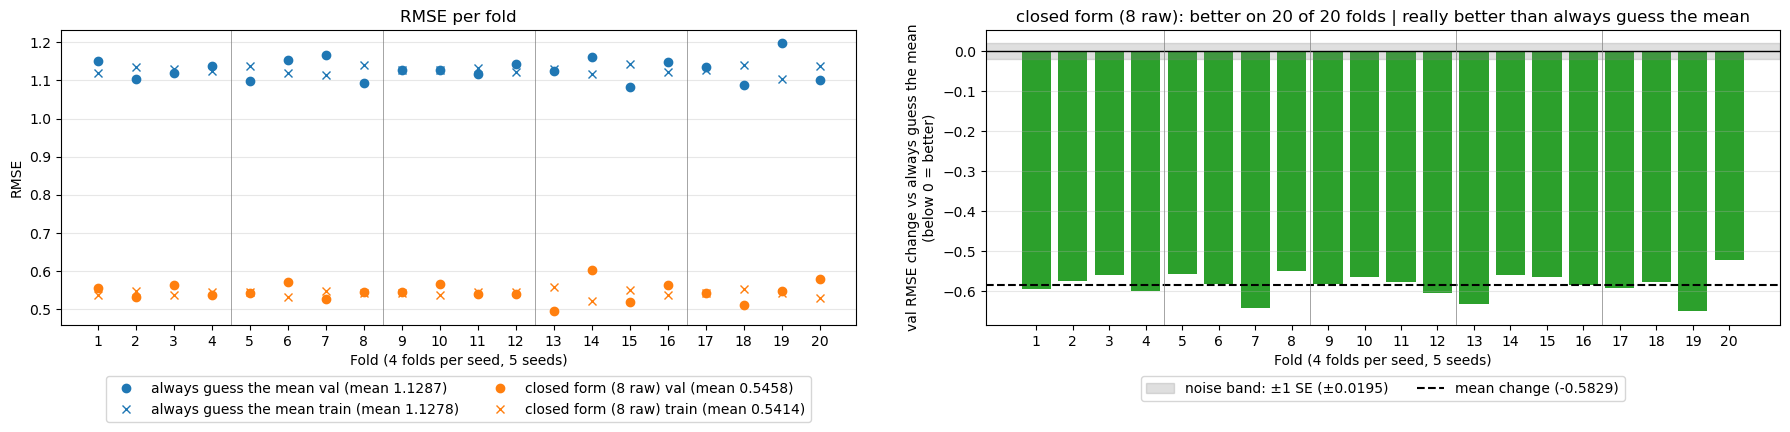

In [4]:
closedform_lr_val_scores, closedform_lr_train_scores = CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=FEATURES,
	estimator=LinearRegression(),
	folds=FOLDS
)

cv_fold_scores(
	baseline=(dummy_val_scores, dummy_train_scores),
	compare=(closedform_lr_val_scores, closedform_lr_train_scores),
	baseline_name="always guess the mean",
	compare_name="closed form (8 raw)",
)

# Stochastic Gradient Descent (SGD)

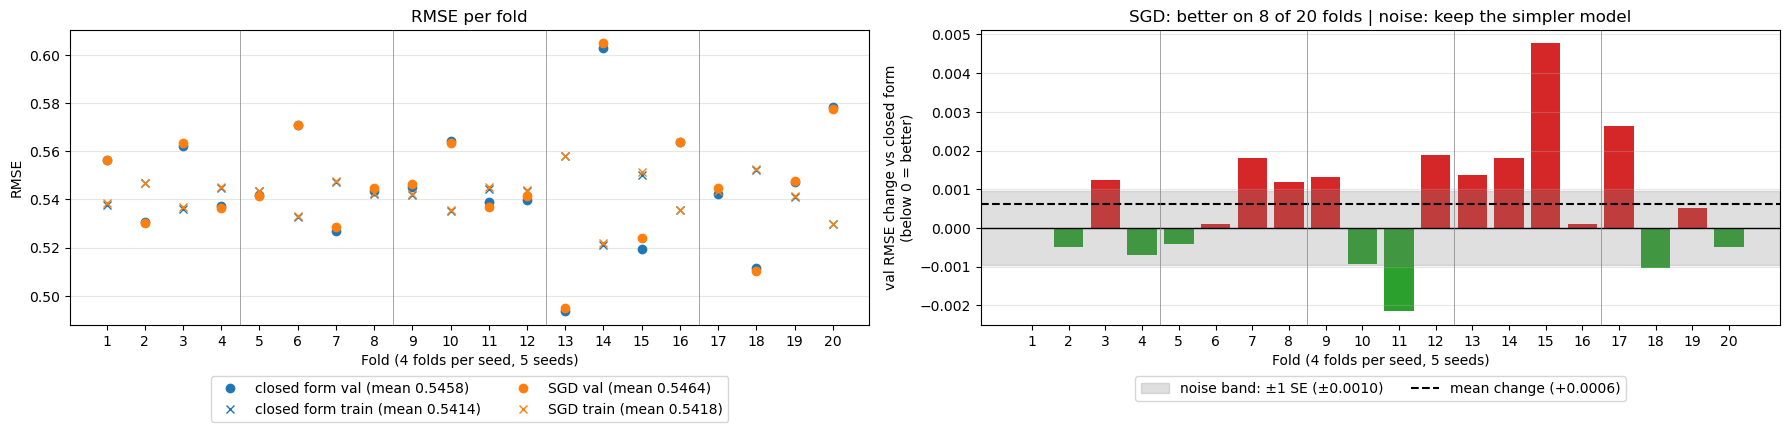

In [5]:
sgd_val_scores, sgd_train_scores = CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=FEATURES,
	estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty=None, random_state=42)),
	folds=FOLDS
)

cv_fold_scores(
	baseline=(closedform_lr_val_scores, closedform_lr_train_scores),
	compare=(sgd_val_scores, sgd_train_scores),
	baseline_name="closed form",
	compare_name="SGD",
)

## Lasso

In [6]:
lasso_scores = {}

### Lasso > Penalty

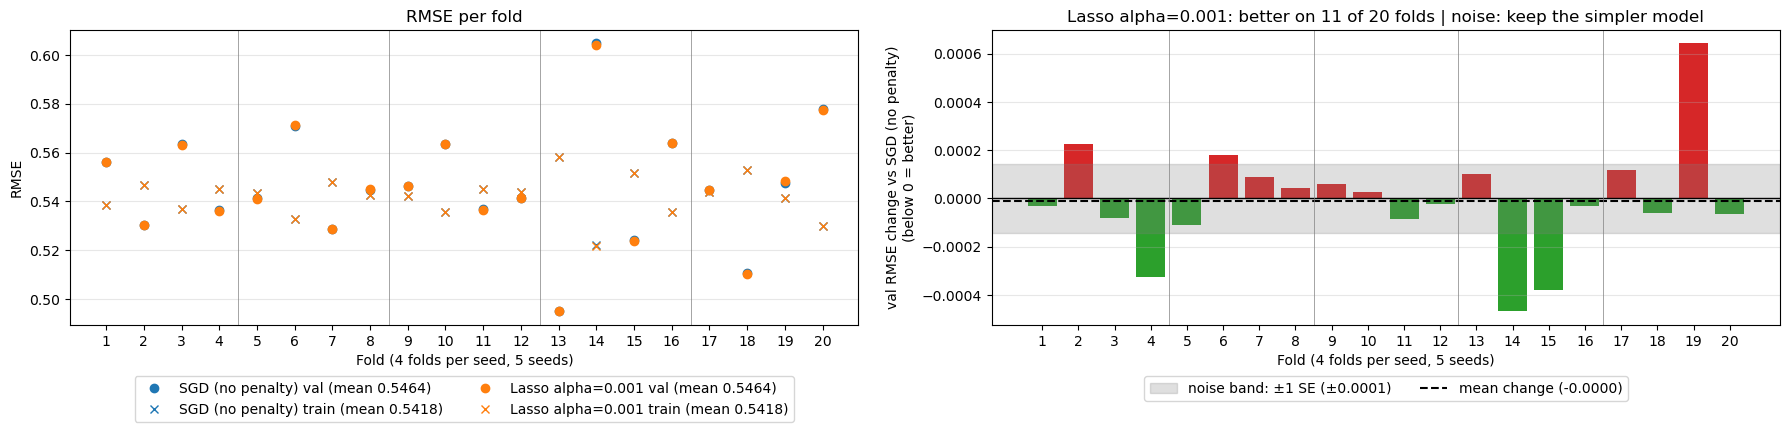

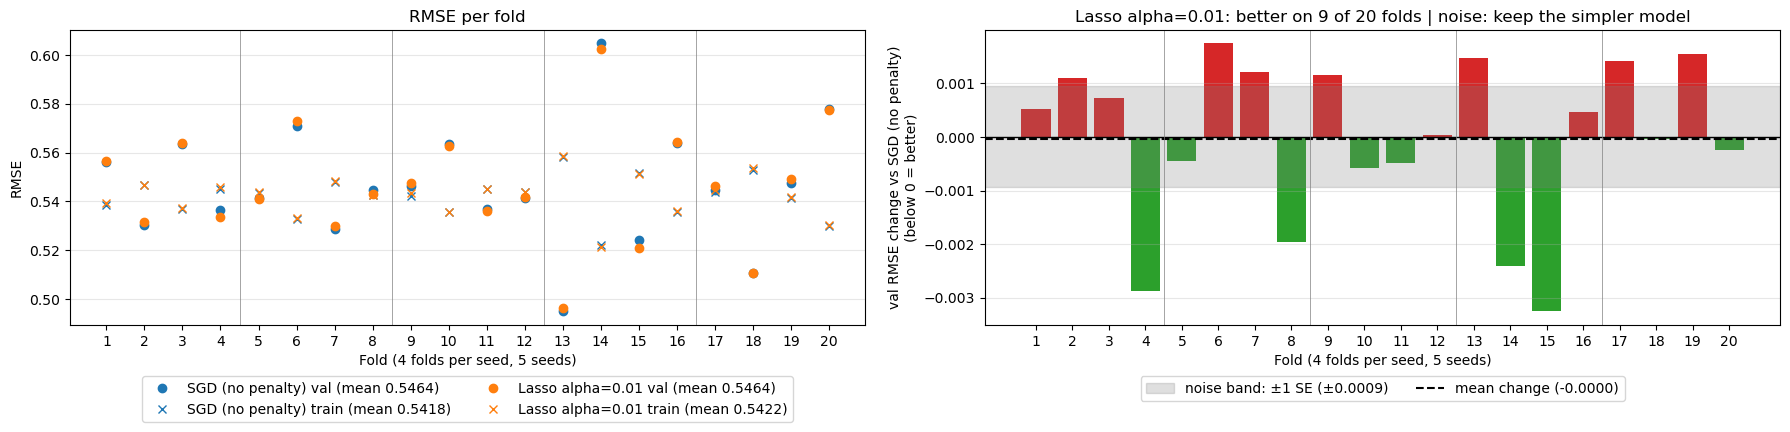

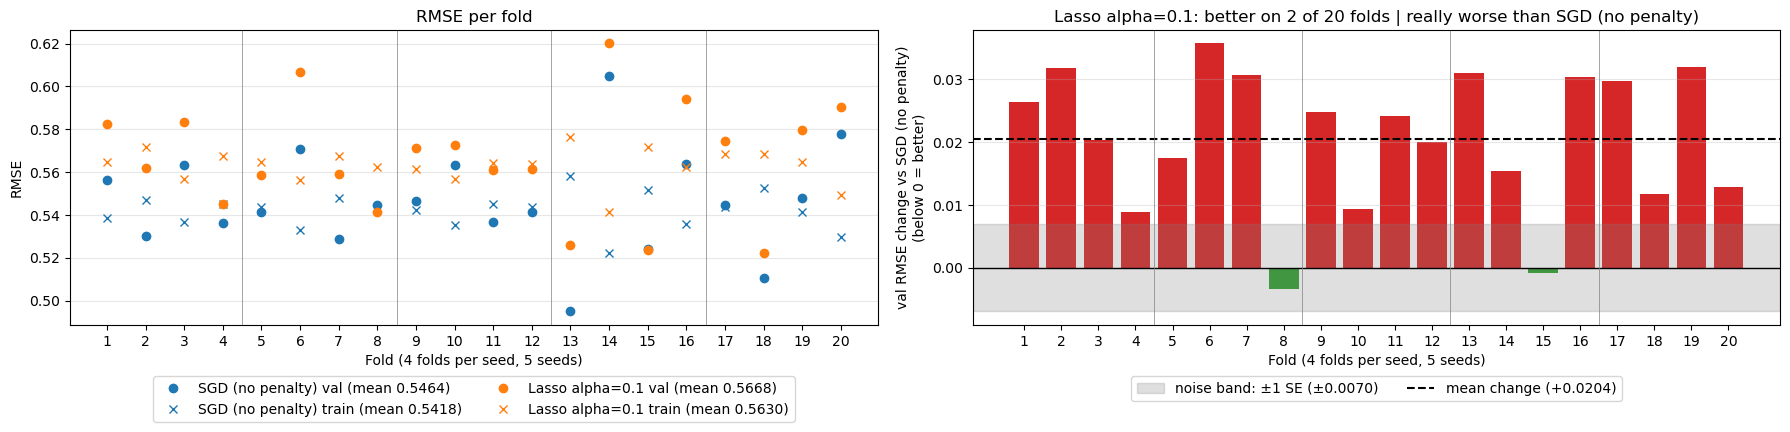

In [7]:
for alpha in ALPHAS:
	lasso_scores[("alpha", alpha)] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='l1', alpha=alpha, random_state=42)),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=lasso_scores[("alpha", alpha)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Lasso alpha={alpha}",
	)

### Lasso > Learning Rate

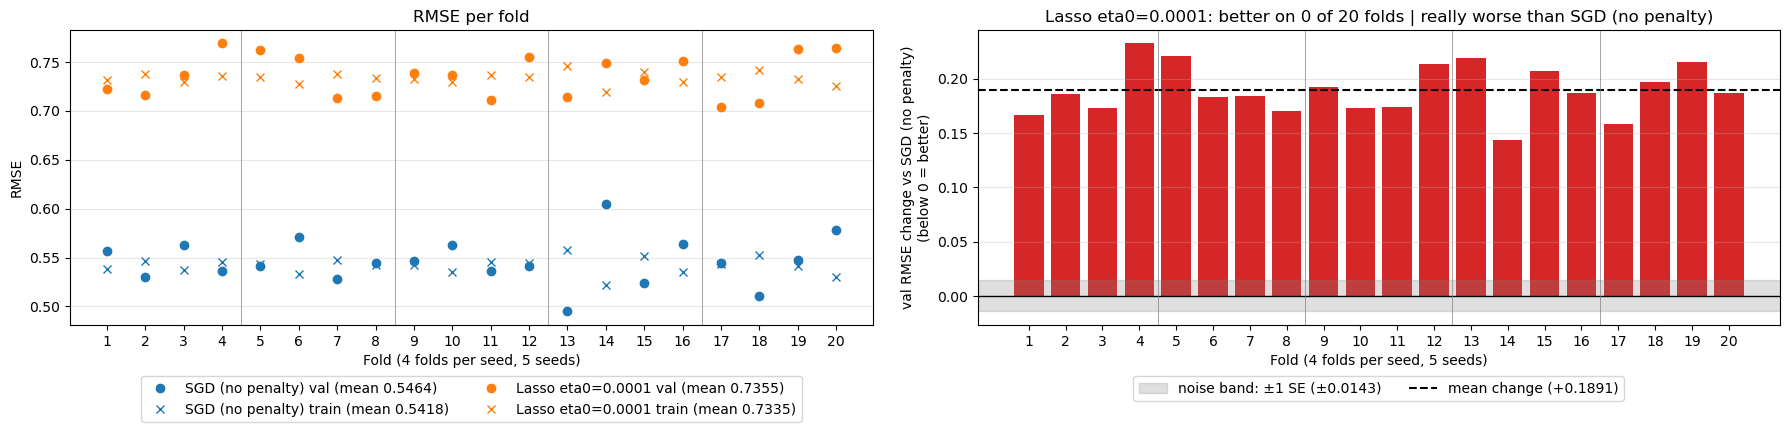

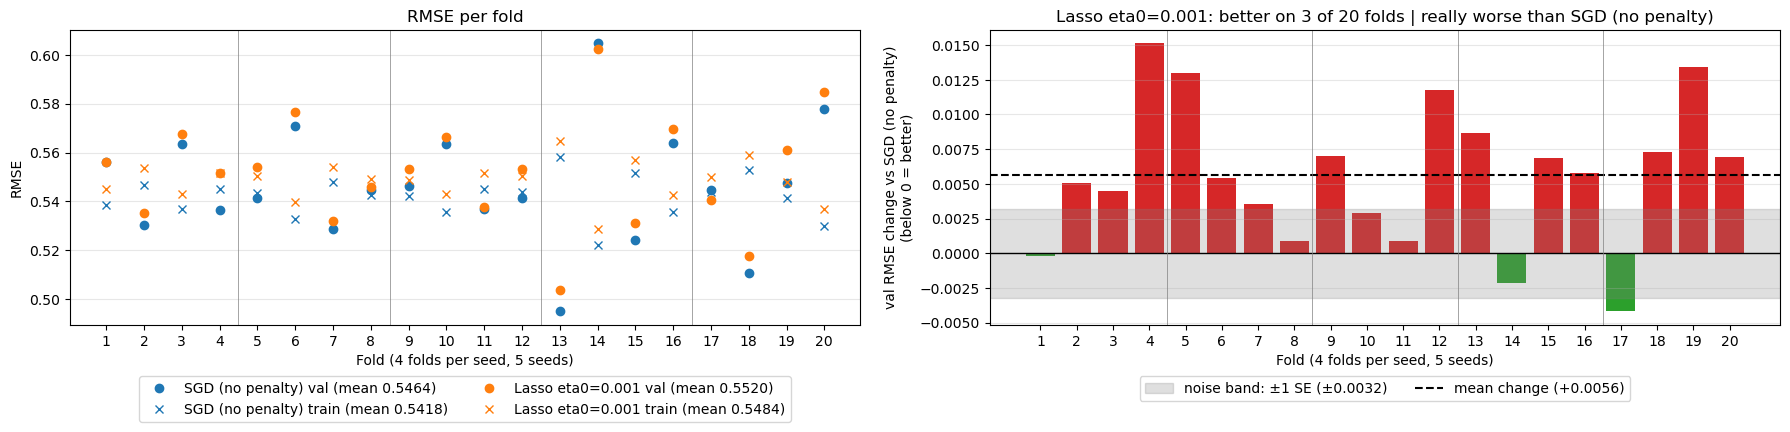

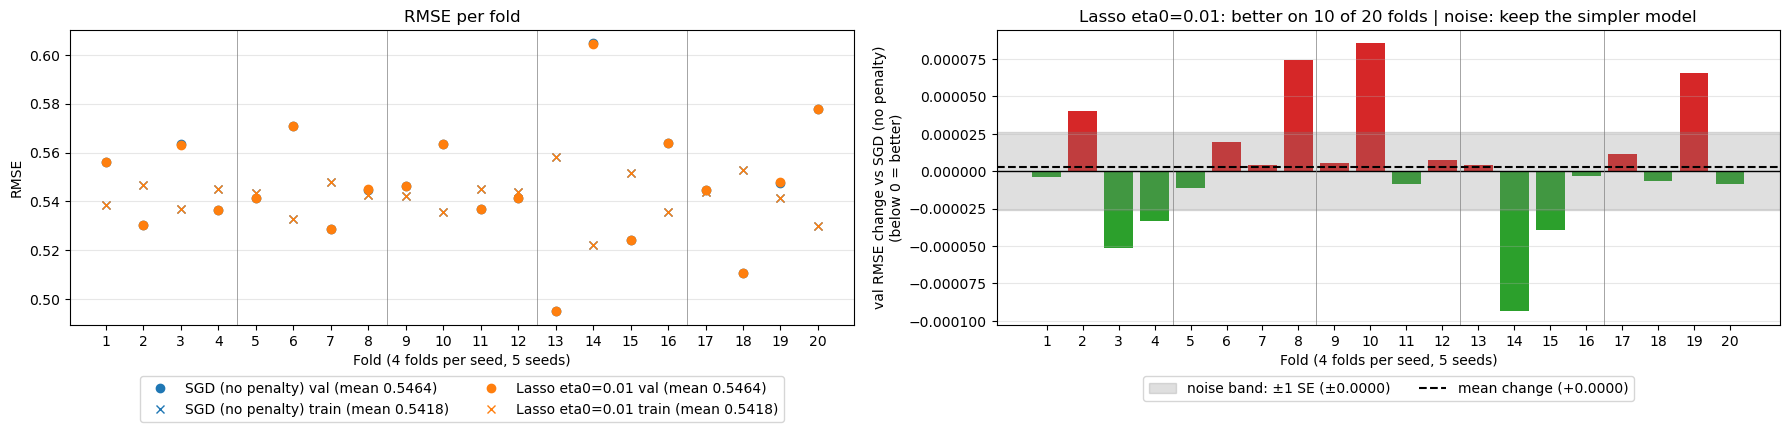

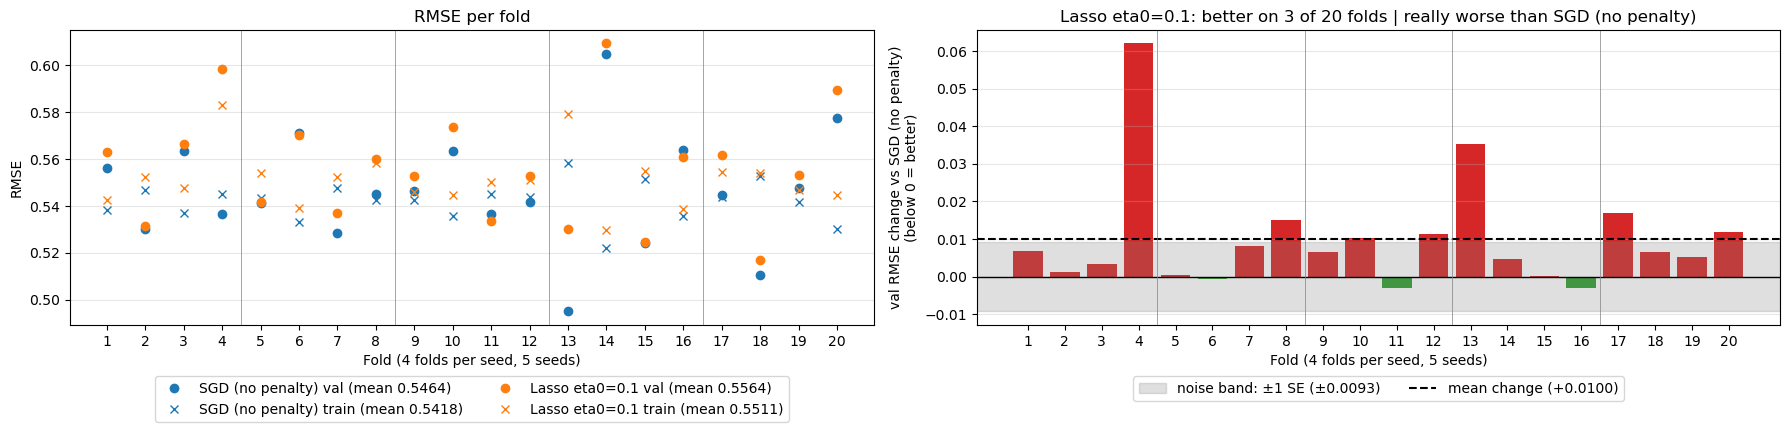

In [8]:
for eta0 in LEARNING_RATES:
	lasso_scores[("eta0", eta0)] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='l1', eta0=eta0, random_state=42)),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=lasso_scores[("eta0", eta0)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Lasso eta0={eta0}",
	)

## Ridge

In [9]:
ridge_scores = {}

### Ridge > Penalty

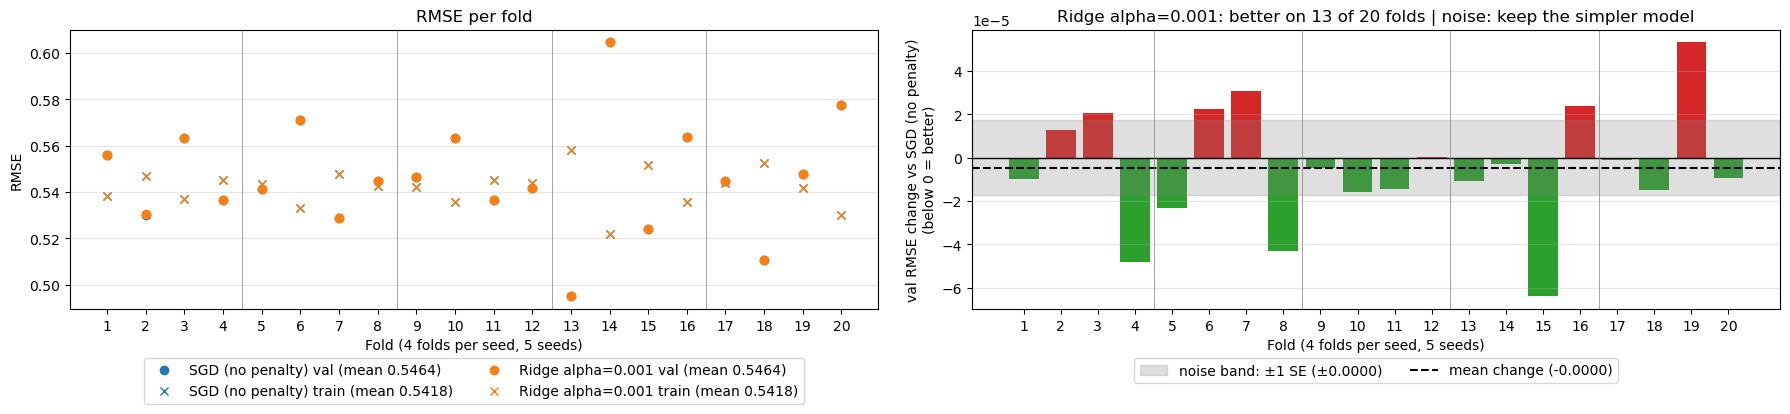

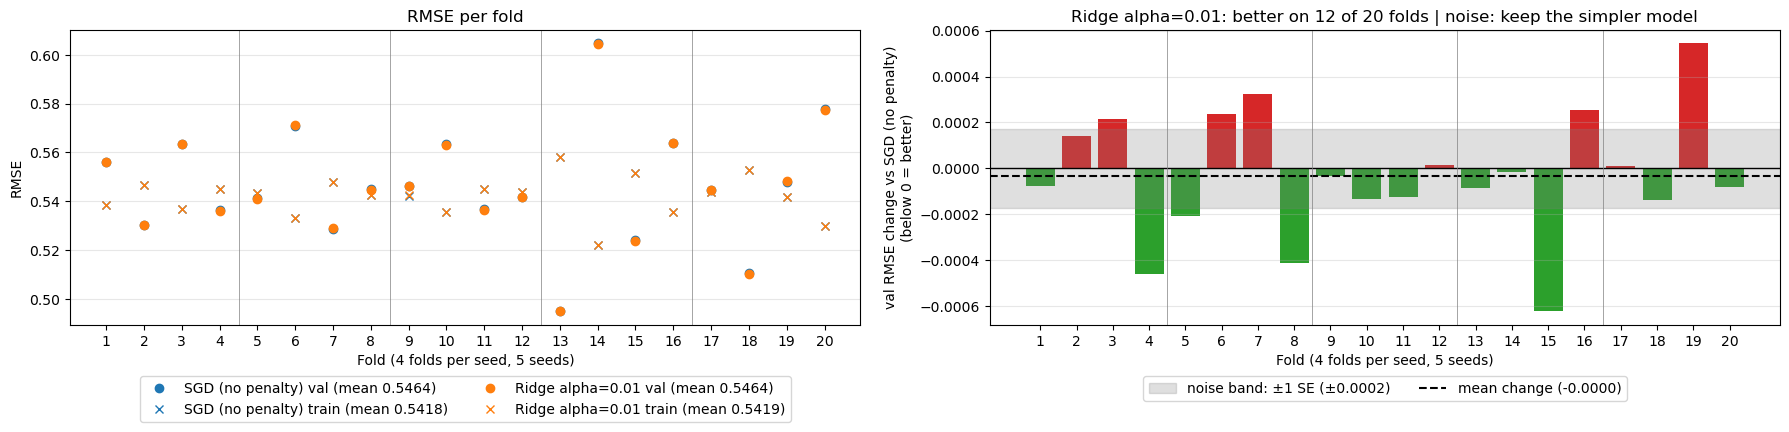

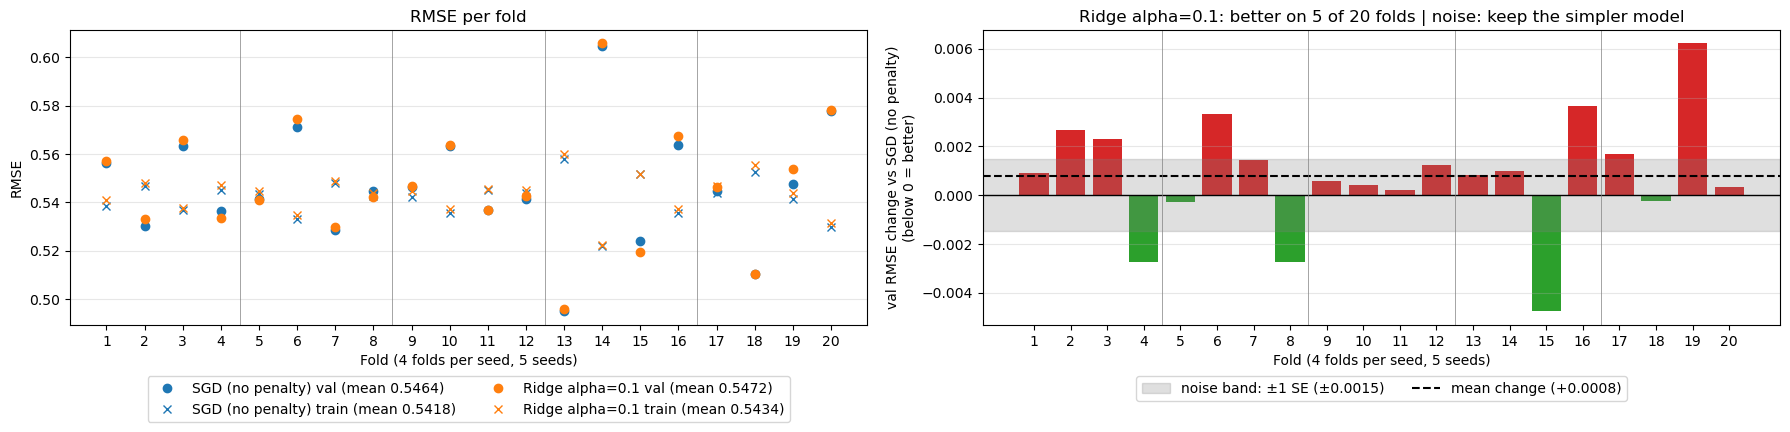

In [10]:
for alpha in ALPHAS:
	ridge_scores[("alpha", alpha)] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='l2', alpha=alpha, random_state=42)),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=ridge_scores[("alpha", alpha)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Ridge alpha={alpha}",
	)

### Ridge > Learning Rate

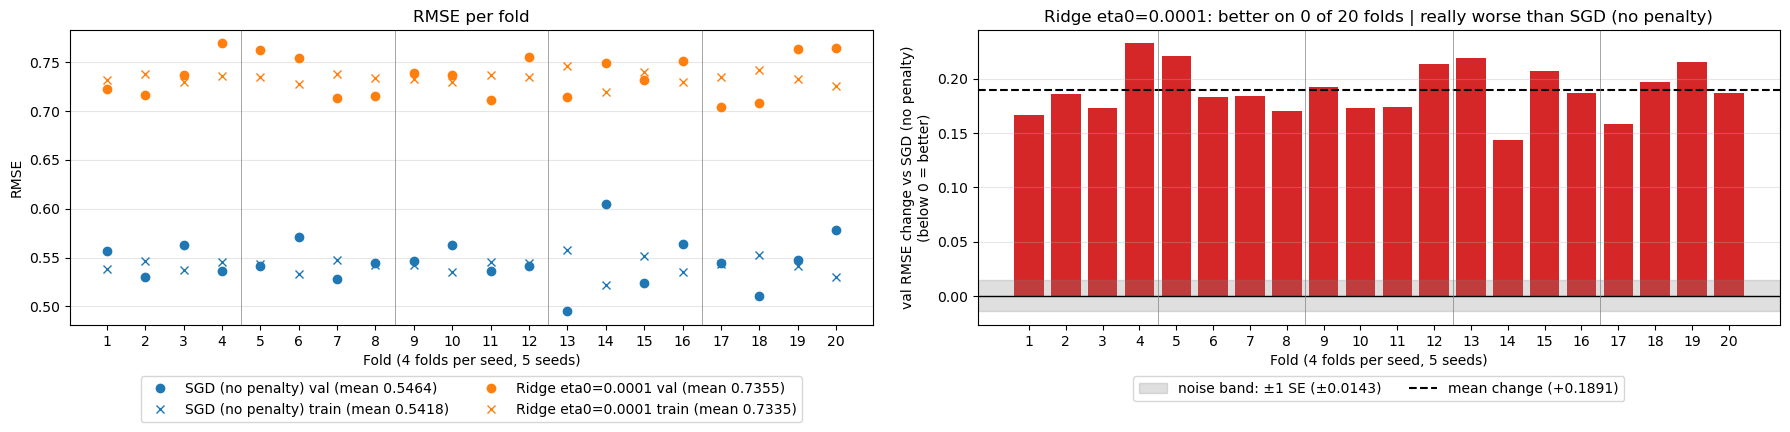

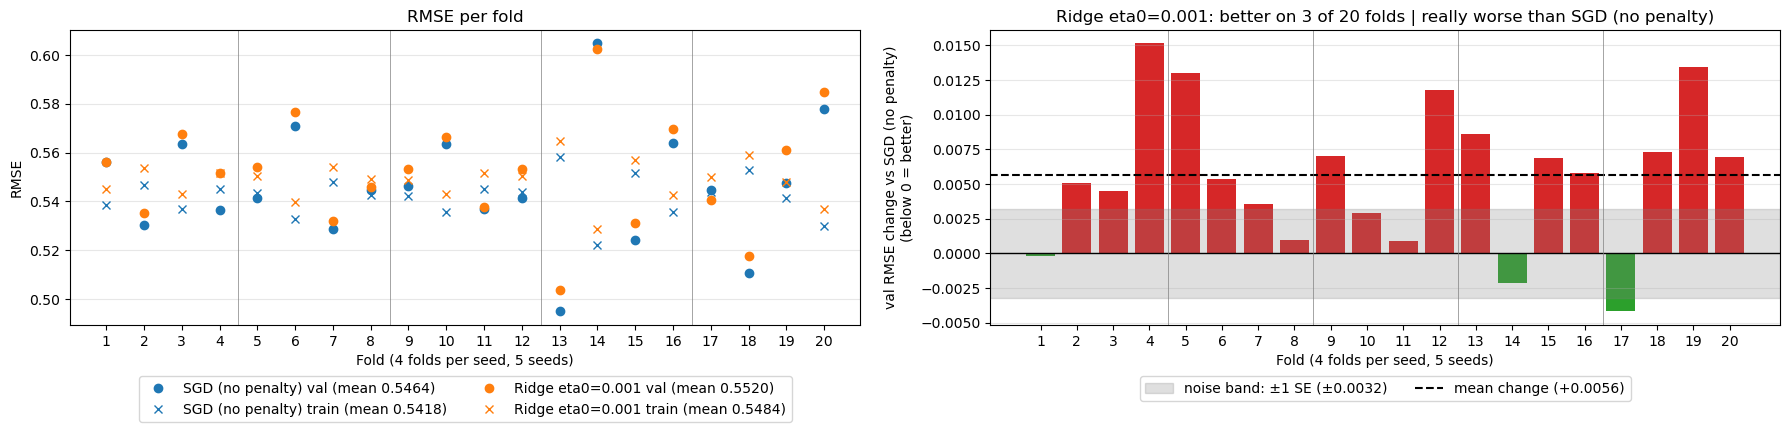

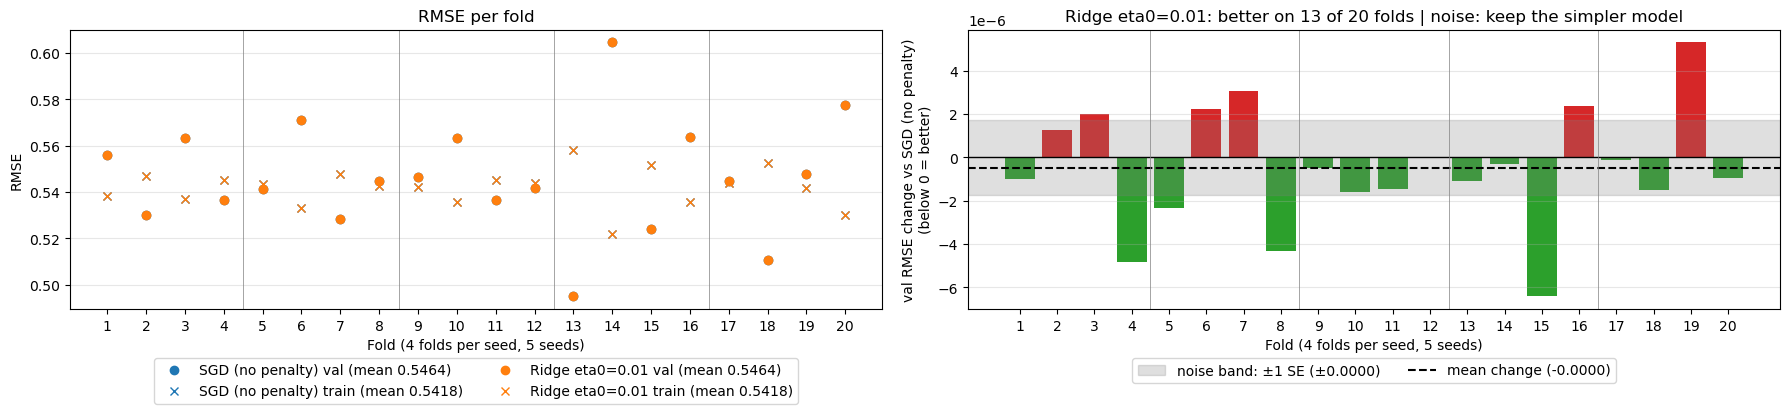

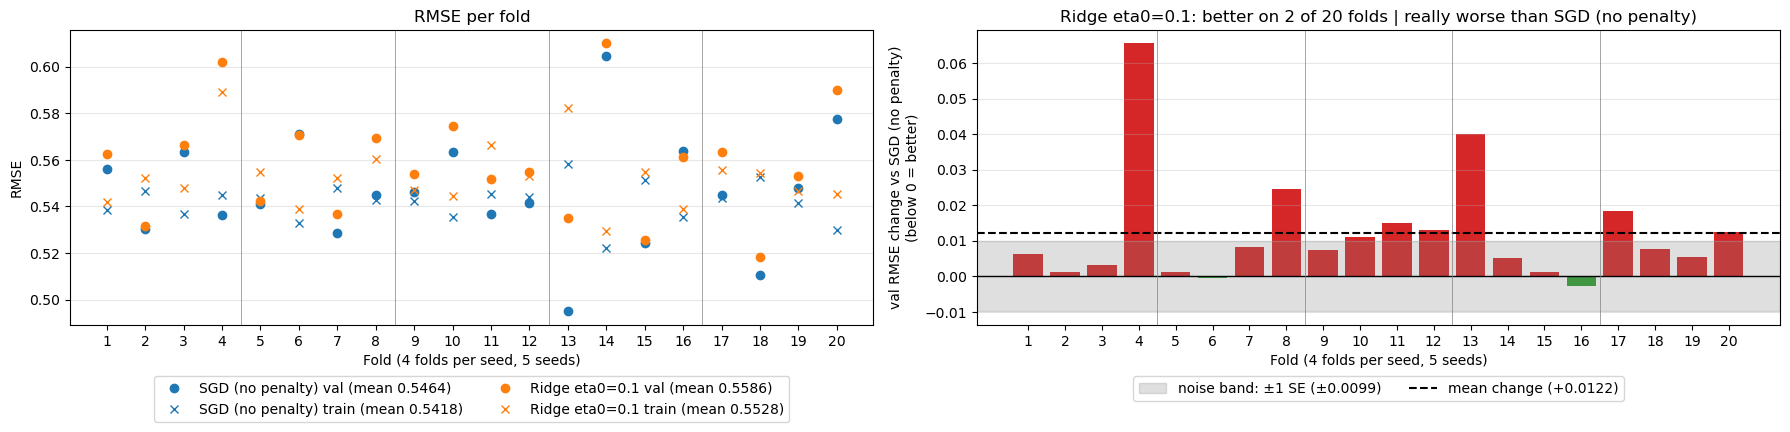

In [11]:
for eta0 in LEARNING_RATES:
	ridge_scores[("eta0", eta0)] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='l2', eta0=eta0, random_state=42)),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=ridge_scores[("eta0", eta0)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Ridge eta0={eta0}",
	)

## Elastic Net

In [12]:
elasticnet_scores = {}

### Elastic Net > Penalty

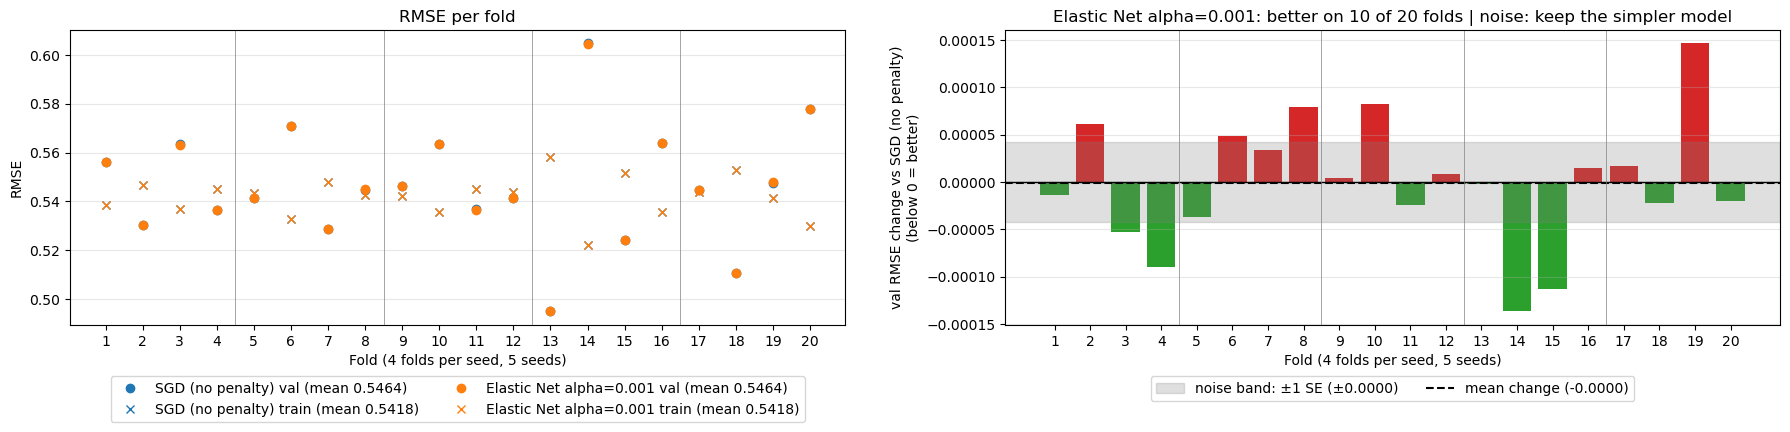

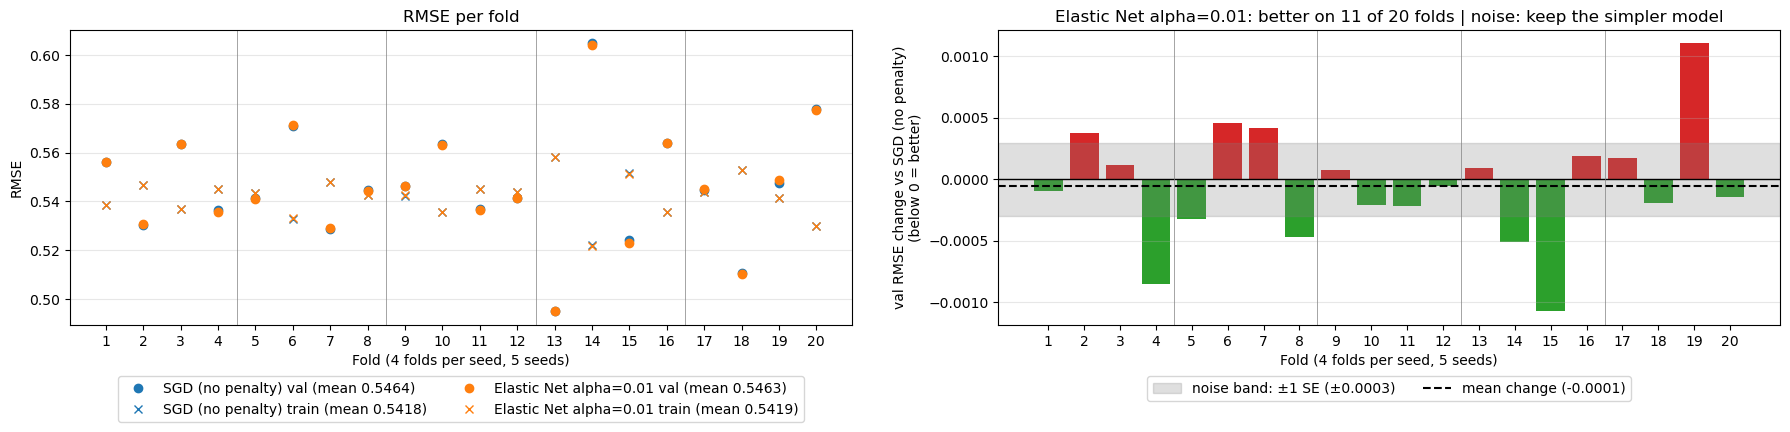

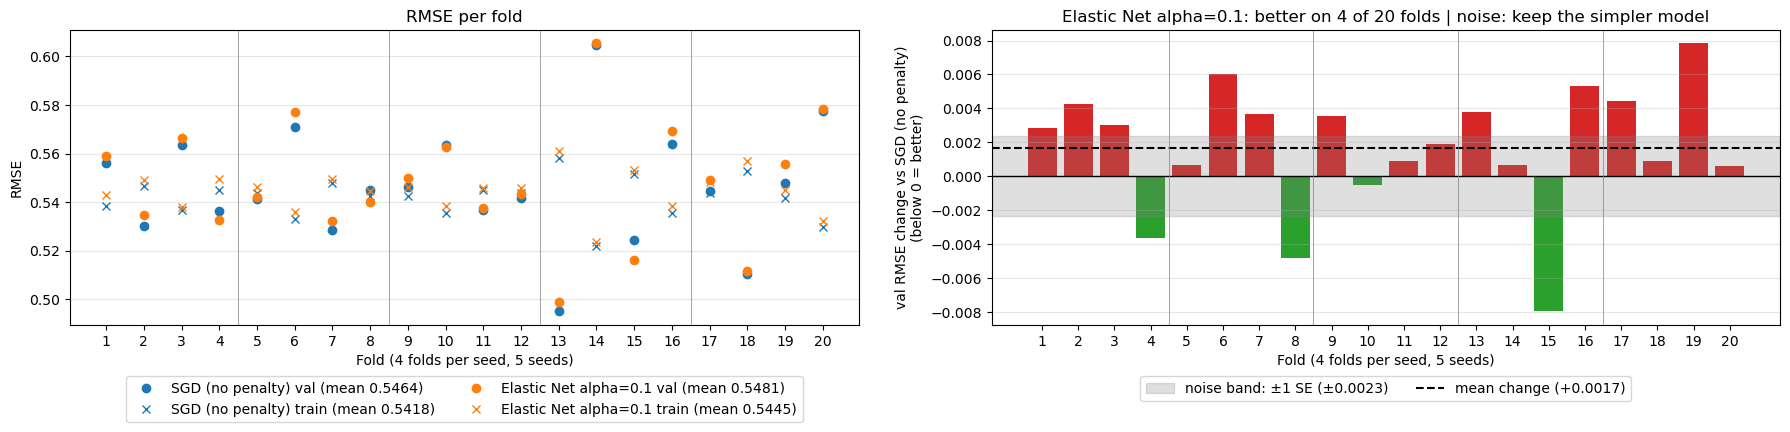

In [13]:
for alpha in ALPHAS:
	elasticnet_scores[("alpha", alpha)] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='elasticnet', alpha=alpha, random_state=42)),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=elasticnet_scores[("alpha", alpha)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Elastic Net alpha={alpha}",
	)

### Elastic Net > Learning Rate

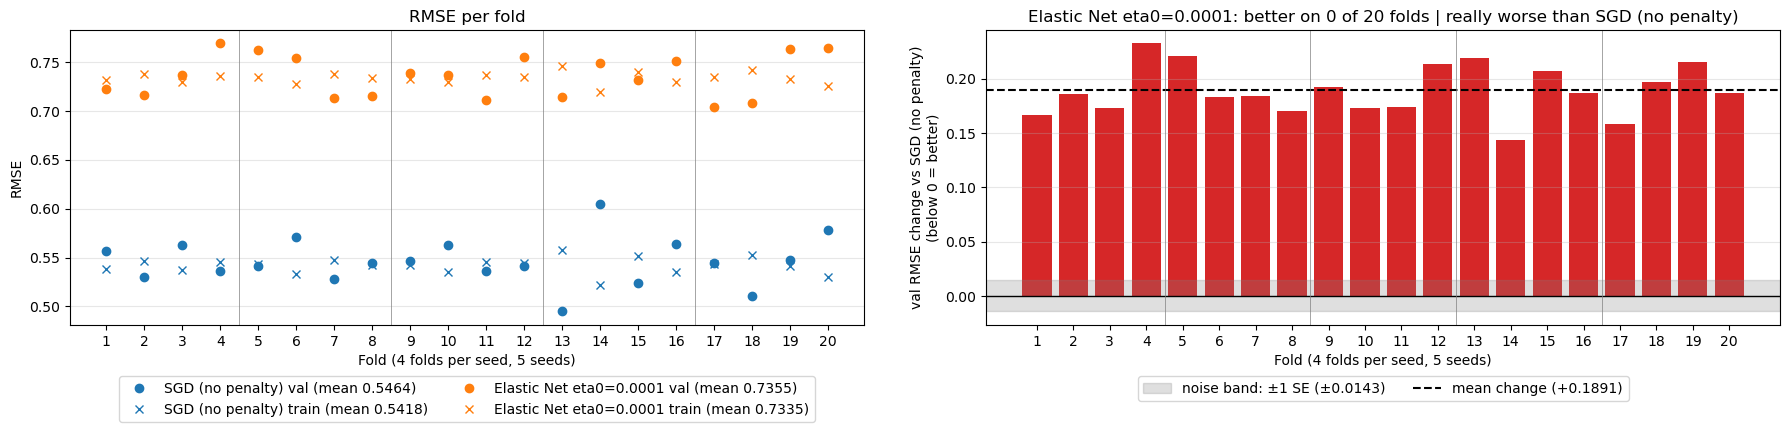

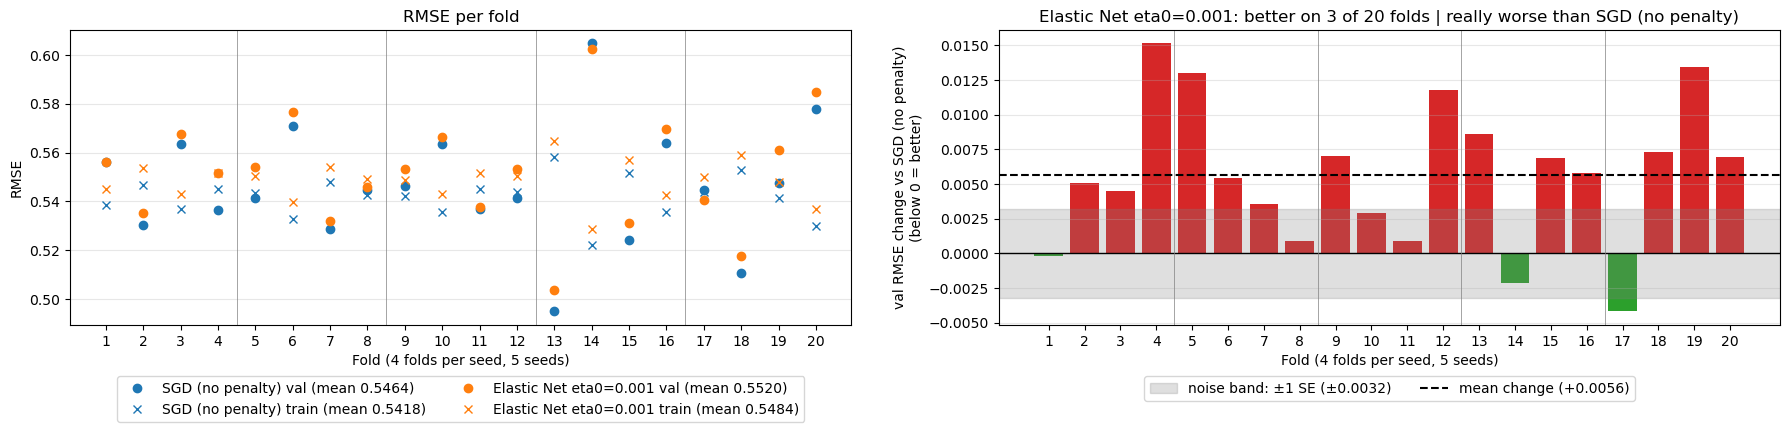

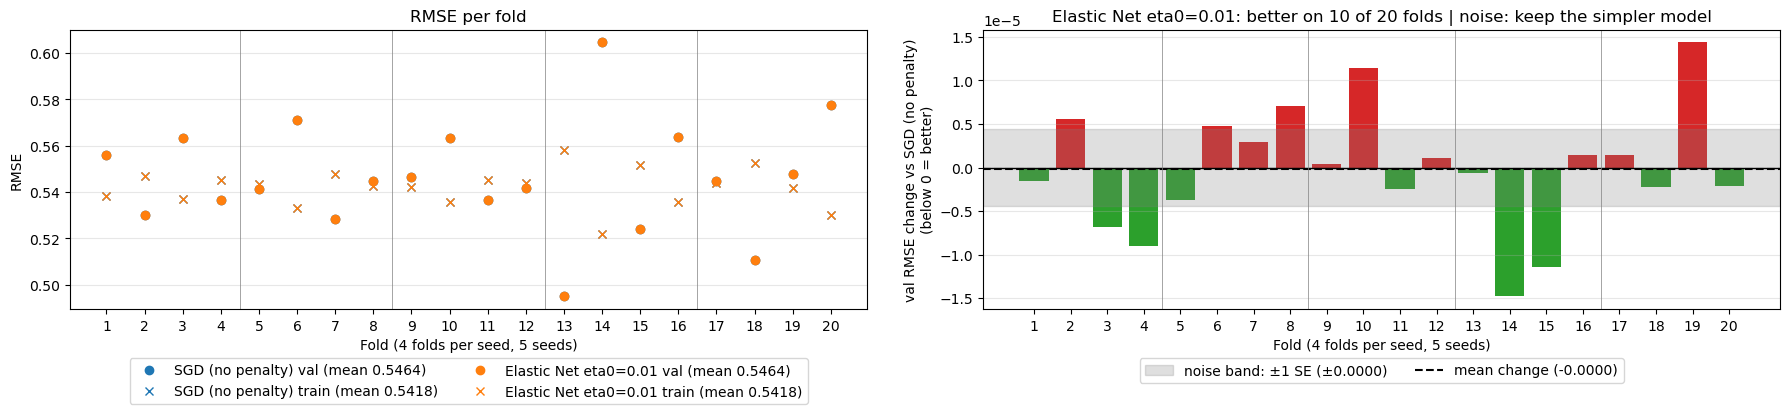

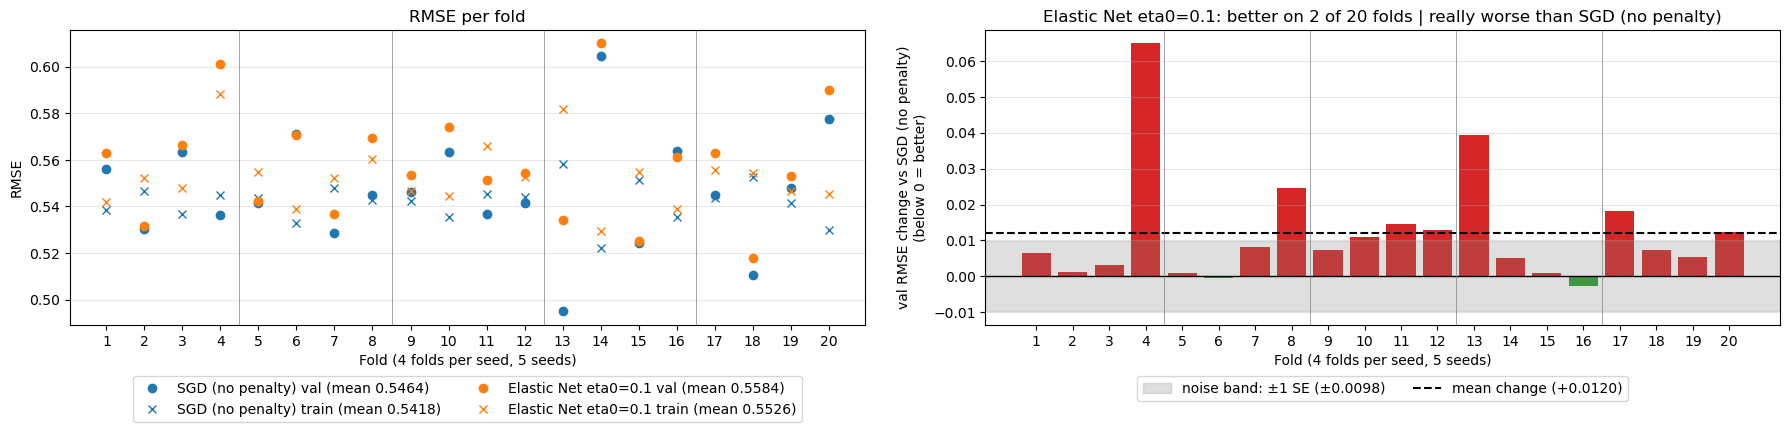

In [14]:
for eta0 in LEARNING_RATES:
	elasticnet_scores[("eta0", eta0)] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='elasticnet', eta0=eta0, random_state=42)),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=elasticnet_scores[("eta0", eta0)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Elastic Net eta0={eta0}",
	)

## Penalty Summary

In [ ]:
runs = {"SGD (no penalty)": (sgd_val_scores, sgd_train_scores)}
for name, scores in [("Ridge", ridge_scores), ("Lasso", lasso_scores), ("Elastic Net", elasticnet_scores)]:
	for (hyperparameter, value), val_train in scores.items():
		if hyperparameter == "alpha":
			runs[f"{name} alpha={value}"] = val_train

summary = pd.DataFrame({
	name: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for name, (val, train) in runs.items()
}).T.sort_values("change vs SGD")
summary["folds better"] = summary["folds better"].astype(int)
summary["change vs SGD"] = summary["change vs SGD"].map(np.format_float_positional)
summary

**Impact of the penalty.** At alpha 0.001 and 0.01, Ridge, Lasso and Elastic Net all score within noise of plain SGD (0.5464): the penalty is too weak to change the coefficients. At alpha 0.1 the penalty starts to hurt. Lasso rises to 0.5668 (+0.0204, SE 0.0070), the only change outside the noise band, because L1 pushes some coefficients to exactly 0. Elastic Net (0.5481) and Ridge (0.5472) rise less and stay within noise. A penalty only helps a model that overfits. Here training RMSE (0.5418) is close to validation RMSE (0.5464), so there is little overfitting to fix, and a stronger penalty just underfits.

## Learning Rate Summary

In [ ]:
learning_rate_runs = {"SGD (no penalty)": (sgd_val_scores, sgd_train_scores)}
for name, scores in [("Ridge", ridge_scores), ("Lasso", lasso_scores), ("Elastic Net", elasticnet_scores)]:
	for (hyperparameter, value), val_train in scores.items():
		if hyperparameter == "eta0":
			learning_rate_runs[f"{name} eta0={value}"] = val_train

learning_rate_summary = pd.DataFrame({
	name: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for name, (val, train) in learning_rate_runs.items()
}).T.sort_values("change vs SGD")
learning_rate_summary["folds better"] = learning_rate_summary["folds better"].astype(int)
learning_rate_summary["change vs SGD"] = learning_rate_summary["change vs SGD"].map(np.format_float_positional)
learning_rate_summary

**Impact of the learning rate.** Each run changes only eta0 and leaves alpha at its default. eta0 0.01 is the value plain SGD already uses, so at 0.01 all three penalties match it (0.5464). Every other value is worse by more than its noise band. At 0.001 all three rise to 0.5520 (+0.0056, SE 0.0032). At 0.1 Lasso rises to 0.5564 (+0.0100, SE 0.0093), Elastic Net to 0.5584 (+0.0120, SE 0.0098) and Ridge to 0.5586 (+0.0122, SE 0.0099), each only narrowly outside its band. At 0.0001 all three reach 0.7355 (+0.1891, SE 0.0143) and are worse on all 20 folds. Training RMSE rises with validation RMSE in every case (0.7335 at 0.0001, against 0.5418 for plain SGD), so a poor learning rate leaves the model underfit, not overfit. The three penalties score almost the same at every eta0, so here the learning rate matters far more than the penalty.

## Hyperparameter Grid
Every combination of penalty, alpha and learning rate (eta0), each compared against plain SGD.

In [16]:
grid_scores = {}
for penalty, alpha, eta0 in product(['l2', 'l1', 'elasticnet'], ALPHAS, LEARNING_RATES):
	grid_scores[(penalty, alpha, eta0)] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty=penalty, alpha=alpha, eta0=eta0, random_state=42)),
		folds=FOLDS
	)

grid = pd.DataFrame({
	key: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for key, (val, train) in grid_scores.items()
}).T
grid.index.names = ["penalty", "alpha", "eta0"]
grid["folds better"] = grid["folds better"].astype(int)
grid.sort_values("val RMSE").round(4)

,,,val RMSE,train RMSE,change vs SGD,SE,folds better
penalty,alpha,eta0,,,,,
elasticnet,0.010,0.0100,0.5463,0.5419,-0.0001,0.0003,11
l1,0.010,0.0100,0.5464,0.5422,-0.0000,0.0009,9
l2,0.010,0.0100,0.5464,0.5419,-0.0000,0.0002,12
l1,0.001,0.0100,0.5464,0.5418,-0.0000,0.0001,11
l2,0.001,0.0100,0.5464,0.5418,-0.0000,0.0000,13
elasticnet,0.001,0.0100,0.5464,0.5418,-0.0000,0.0000,10
l2,0.100,0.0100,0.5472,0.5434,0.0008,0.0015,5
elasticnet,0.100,0.0100,0.5481,0.5445,0.0017,0.0023,4
l1,0.010,0.0010,0.5517,0.5485,0.0053,0.0031,4


### Elastic Net l1_ratio
Elastic Net only: l1_ratio sets the mix of the two penalties (0 = all Ridge, 1 = all Lasso). Ridge and Lasso ignore it.

In [17]:
L1_RATIOS = [0.15, 0.5, 0.85]

elasticnet_grid_scores = {}
for alpha, eta0, l1_ratio in product(ALPHAS, LEARNING_RATES, L1_RATIOS):
	elasticnet_grid_scores[(alpha, eta0, l1_ratio)] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='elasticnet', alpha=alpha, eta0=eta0, l1_ratio=l1_ratio, random_state=42)),
		folds=FOLDS
	)

elasticnet_grid = pd.DataFrame({
	key: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for key, (val, train) in elasticnet_grid_scores.items()
}).T
elasticnet_grid.index.names = ["alpha", "eta0", "l1_ratio"]
elasticnet_grid["folds better"] = elasticnet_grid["folds better"].astype(int)
elasticnet_grid.sort_values("val RMSE").round(4)

val RMSE  train RMSE  change vs SGD      SE  \
alpha eta0   l1_ratio                                                
0.010 0.0100 0.50        0.5463      0.5420        -0.0001  0.0005   
             0.85        0.5463      0.5421        -0.0001  0.0008   
             0.15        0.5463      0.5419        -0.0001  0.0003   
0.001 0.0100 0.85        0.5464      0.5418        -0.0000  0.0001   
             0.50        0.5464      0.5418        -0.0000  0.0001   
             0.15        0.5464      0.5418        -0.0000  0.0000   
0.100 0.0100 0.15        0.5481      0.5445         0.0017  0.0023   
0.010 0.0010 0.85        0.5517      0.5485         0.0053  0.0031   
             0.50        0.5518      0.5485         0.0054  0.0031   
             0.15        0.5520      0.5484         0.0056  0.0032   
0.001 0.0010 0.85        0.5520      0.5484         0.0056  0.0032   
             0.50        0.5520      0.5484         0.0056  0.0032   
             0.15        0.5520      0.5484         0.0056  0.0032   
0.100 0.0010 0.15        0.5536      0.5505         0.0072  0.0036   
      0.0100 0.50        0.5536      0.5498         0.0072  0.0043   
0.010 0.1000 0.15        0.5548      0.5507         0.0084  0.0089   
             0.85        0.5549      0.5505         0.0085  0.0084   
             0.50        0.5549      0.5505         0.0085  0.0085   
0.100 0.1000 0.50        0.5554      0.5517         0.0090  0.0089   
0.001 0.1000 0.85        0.5564      0.5513         0.0100  0.0089   
             0.15        0.5568      0.5516         0.0104  0.0089   
             0.50        0.5569      0.5520         0.0105  0.0089   
0.100 0.1000 0.15        0.5572      0.5532         0.0108  0.0093   
      0.0010 0.50        0.5584      0.5553         0.0120  0.0048   
      0.0100 0.85        0.5623      0.5584         0.0159  0.0060   
      0.1000 0.85        0.5656      0.5610         0.0192  0.0118   
      0.0010 0.85        0.5673      0.5641         0.0209  0.0066   
0.001 0.0001 0.15        0.7355      0.7335         0.1891  0.0143   
             0.50        0.7355      0.7335         0.1891  0.0143   
             0.85        0.7355      0.7335         0.1891  0.0143   
0.010 0.0001 0.15        0.7356      0.7335         0.1892  0.0143   
             0.50        0.7356      0.7336         0.1892  0.0143   
             0.85        0.7357      0.7336         0.1893  0.0144   
0.100 0.0001 0.15        0.7368      0.7348         0.1904  0.0145   
             0.50        0.7406      0.7386         0.1942  0.0150   
             0.85        0.7463      0.7443         0.1999  0.0161   

                       folds better  
alpha eta0   l1_ratio                
0.010 0.0100 0.50                10  
             0.85                 9  
             0.15                11  
0.001 0.0100 0.85                11  
             0.50                11  
             0.15                10  
0.100 0.0100 0.15                 4  
0.010 0.0010 0.85                 4  
             0.50                 4  
             0.15                 3  
0.001 0.0010 0.85                 3  
             0.50                 3  
             0.15                 3  
0.100 0.0010 0.15                 3  
      0.0100 0.50                 3  
0.010 0.1000 0.15                 5  
             0.85                 5  
             0.50                 5  
0.100 0.1000 0.50                 4  
0.001 0.1000 0.85                 4  
             0.15                 3  
             0.50                 4  
0.100 0.1000 0.15                 4  
      0.0010 0.50                 1  
      0.0100 0.85                 2  
      0.1000 0.85                 1  
      0.0010 0.85                 1  
0.001 0.0001 0.15                 0  
             0.50                 0  
             0.85                 0  
0.010 0.0001 0.15                 0  
             0.50                 0  
             0.85                 0  
0.100 0.0001 0.15               